# Task 1: Image Restoration and Segmentation

**Assignment:** CCA 3 — Computer Vision  
**Unit:** 3

## Objectives
- Load and inspect the original photograph.
- Add Gaussian and salt-and-pepper noise.
- Restore images using median and Gaussian filtering.
- Evaluate restoration using PSNR and SSIM.
- Perform thresholding, morphological operations, edge detection and watershed segmentation.

In [2]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


ERROR: Exception:
Traceback (most recent call last):
  File "c:\Users\shive\AppData\Local\Programs\Python\Python310\lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "c:\Users\shive\AppData\Local\Programs\Python\Python310\lib\site-packages\pip\_vendor\urllib3\response.py", line 519, in read
    data = self._fp.read(amt) if not fp_closed else b""
  File "c:\Users\shive\AppData\Local\Programs\Python\Python310\lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 62, in read
    data = self.__fp.read(amt)
  File "c:\Users\shive\AppData\Local\Programs\Python\Python310\lib\http\client.py", line 464, in read
    s = self.fp.read(amt)
  File "c:\Users\shive\AppData\Local\Programs\Python\Python310\lib\socket.py", line 705, in readinto
    return self._sock.recv_into(b)
  File "c:\Users\shive\AppData\Local\Programs\Python\Python310\lib\ssl.py", line 1273, in recv_into
    return self.read(nbytes, buffer)
  File "c:\Users\shive\AppData\Lo

In [2]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--default-timeout=120",
    "--retries", "5",
    "opencv-python"
])

0

In [2]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--default-timeout=120",
    "--retries", "5",
    "numpy",
    "matplotlib",
    "scikit-image"
])

0

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

print("All libraries imported successfully!")
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

All libraries imported successfully!
OpenCV: 5.0.0
NumPy: 2.2.6


In [4]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Find the project directory
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_DIR = CURRENT_DIR.parent
elif (CURRENT_DIR / "data" / "images").exists():
    PROJECT_DIR = CURRENT_DIR
else:
    PROJECT_DIR = CURRENT_DIR.parent

IMAGE_PATH = PROJECT_DIR / "data" / "images" / "original.jpeg"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "task1_restoration_segmentation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 11

print("Project directory:", PROJECT_DIR.resolve())
print("Image path:", IMAGE_PATH.resolve())
print("Image exists:", IMAGE_PATH.exists())
print("Output directory:", OUTPUT_DIR.resolve())

Project directory: D:\Projects\CV
Image path: D:\Projects\CV\data\images\original.jpeg
Image exists: True
Output directory: D:\Projects\CV\outputs\task1_restoration_segmentation


Image loaded successfully!
Image dimensions (height, width, channels): (1280, 721, 3)
Data type: uint8


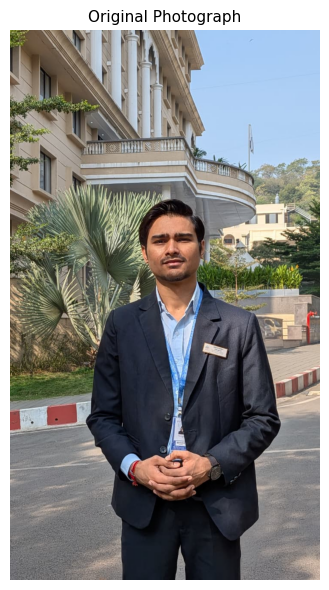

In [5]:
original_bgr = cv2.imread(str(IMAGE_PATH))

if original_bgr is None:
    raise FileNotFoundError(
        f"Could not load image: {IMAGE_PATH.resolve()}\n"
        "Check the filename and folder location."
    )

# Convert BGR to RGB for correct Matplotlib display
original = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)

# Grayscale image for later processing
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

print("Image loaded successfully!")
print("Image dimensions (height, width, channels):", original.shape)
print("Data type:", original.dtype)

plt.figure(figsize=(8, 6))
plt.imshow(original)
plt.title("Original Photograph")
plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_original_image.png", dpi=150, bbox_inches="tight")
plt.show()

### Observation

The original photograph is loaded and used as the reference image.
The processed images will be compared against this reference to evaluate
the effects of noise, filtering, thresholding, and segmentation.

In [6]:
# Fixed random seed for reproducible results
rng = np.random.default_rng(42)

# 1. Gaussian noise
gaussian_noise = rng.normal(
    loc=0,
    scale=20,
    size=original.shape
)

gaussian_noisy = np.clip(
    original.astype(np.float32) + gaussian_noise,
    0,
    255
).astype(np.uint8)

# 2. Salt-and-pepper noise
salt_pepper_noisy = original.copy()

noise_amount = 0.04  # 4% of image pixels
random_map = rng.random(original.shape[:2])

salt_mask = random_map < (noise_amount / 2)
pepper_mask = (
    (random_map >= noise_amount / 2)
    & (random_map < noise_amount)
)

salt_pepper_noisy[salt_mask] = [255, 255, 255]
salt_pepper_noisy[pepper_mask] = [0, 0, 0]

print("Gaussian noise added.")
print("Salt-and-pepper noise added.")

Gaussian noise added.
Salt-and-pepper noise added.


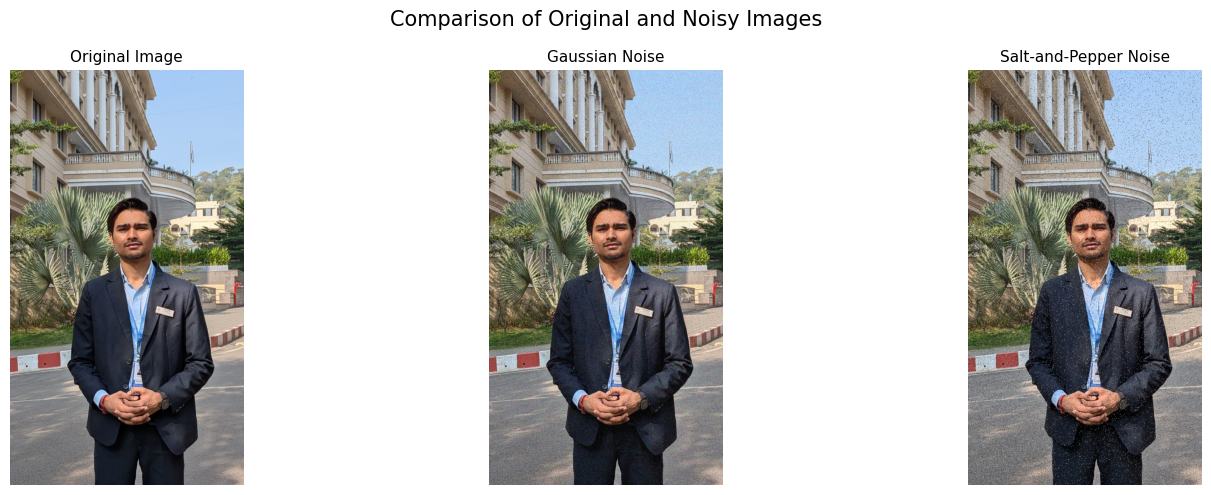

True

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original)
axes[0].set_title("Original Image")

axes[1].imshow(gaussian_noisy)
axes[1].set_title("Gaussian Noise")

axes[2].imshow(salt_pepper_noisy)
axes[2].set_title("Salt-and-Pepper Noise")

for ax in axes:
    ax.axis("off")

fig.suptitle("Comparison of Original and Noisy Images", fontsize=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_noise_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Save processed images
cv2.imwrite(
    str(OUTPUT_DIR / "03_gaussian_noisy.png"),
    cv2.cvtColor(gaussian_noisy, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "04_salt_pepper_noisy.png"),
    cv2.cvtColor(salt_pepper_noisy, cv2.COLOR_RGB2BGR)
)

### Observation

Compare the noisy images with the original photograph.

- Gaussian noise creates random variations in pixel intensity.
- Salt-and-pepper noise introduces isolated black and white pixels.
- The following section applies Gaussian and median filtering to reduce
  these distortions.

## Part 2: Image Restoration

Gaussian filtering smooths an image by applying a weighted averaging
operation. It is commonly used to reduce Gaussian noise.

Median filtering replaces each pixel with the median value in its
neighborhood. It is particularly useful for reducing salt-and-pepper noise.

The results are compared with the original image using PSNR and SSIM.

In [8]:
# Gaussian filtering
gaussian_restored = cv2.GaussianBlur(
    gaussian_noisy,
    (5, 5),
    sigmaX=1.0
)

# Median filtering
median_restored = cv2.medianBlur(
    salt_pepper_noisy,
    5
)

print("Gaussian filtering completed.")
print("Median filtering completed.")

Gaussian filtering completed.
Median filtering completed.


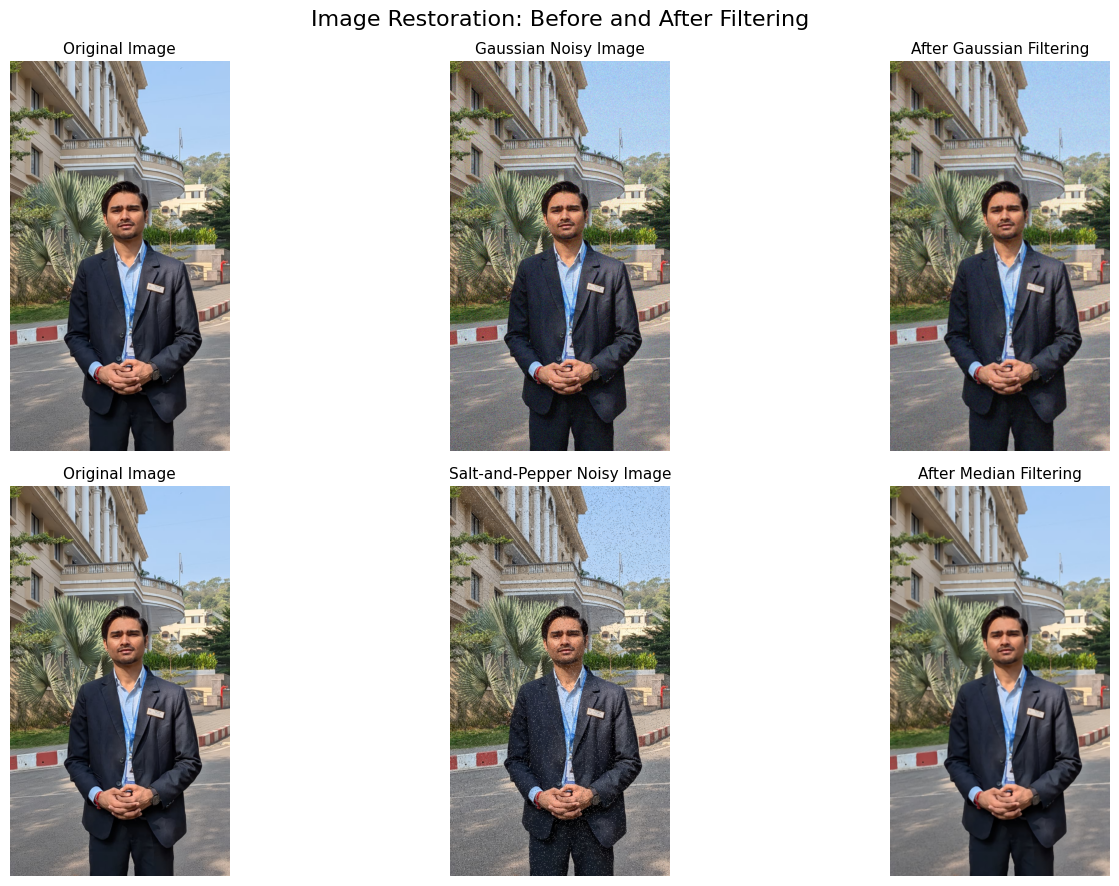

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# First row: Gaussian noise restoration
axes[0, 0].imshow(original)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(gaussian_noisy)
axes[0, 1].set_title("Gaussian Noisy Image")

axes[0, 2].imshow(gaussian_restored)
axes[0, 2].set_title("After Gaussian Filtering")

# Second row: salt-and-pepper restoration
axes[1, 0].imshow(original)
axes[1, 0].set_title("Original Image")

axes[1, 1].imshow(salt_pepper_noisy)
axes[1, 1].set_title("Salt-and-Pepper Noisy Image")

axes[1, 2].imshow(median_restored)
axes[1, 2].set_title("After Median Filtering")

for ax in axes.flat:
    ax.axis("off")

fig.suptitle("Image Restoration: Before and After Filtering", fontsize=16)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_restoration_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
def calculate_metrics(reference, processed):
    psnr_value = peak_signal_noise_ratio(
        reference,
        processed,
        data_range=255
    )

    ssim_value = structural_similarity(
        reference,
        processed,
        channel_axis=-1,
        data_range=255
    )

    return psnr_value, ssim_value


results = []

images_to_evaluate = {
    "Gaussian Noisy": gaussian_noisy,
    "Gaussian Restored": gaussian_restored,
    "Salt-and-Pepper Noisy": salt_pepper_noisy,
    "Median Restored": median_restored
}

for name, image in images_to_evaluate.items():
    psnr_value, ssim_value = calculate_metrics(original, image)

    results.append({
        "Image": name,
        "PSNR (dB)": round(psnr_value, 2),
        "SSIM": round(ssim_value, 4)
    })

for result in results:
    print(result)

{'Image': 'Gaussian Noisy', 'PSNR (dB)': np.float64(22.34), 'SSIM': np.float64(0.4658)}
{'Image': 'Gaussian Restored', 'PSNR (dB)': np.float64(27.31), 'SSIM': np.float64(0.7527)}
{'Image': 'Salt-and-Pepper Noisy', 'PSNR (dB)': np.float64(19.01), 'SSIM': np.float64(0.4795)}
{'Image': 'Median Restored', 'PSNR (dB)': np.float64(25.99), 'SSIM': np.float64(0.7675)}


## Part 3: Image Thresholding

Thresholding converts a grayscale image into a binary image.
Pixels above the selected threshold become white, while pixels below
the threshold become black.

This creates a binary mask that can be used for morphological
operations and segmentation.

In [12]:
# Convert original image to grayscale if needed
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

# Global binary thresholding
_, binary_threshold = cv2.threshold(
    gray,
    127,
    255,
    cv2.THRESH_BINARY
)

# Otsu's automatic threshold selection
otsu_value, otsu_threshold = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Adaptive thresholding
adaptive_threshold = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

print("Otsu threshold selected:", otsu_value)

Otsu threshold selected: 110.0


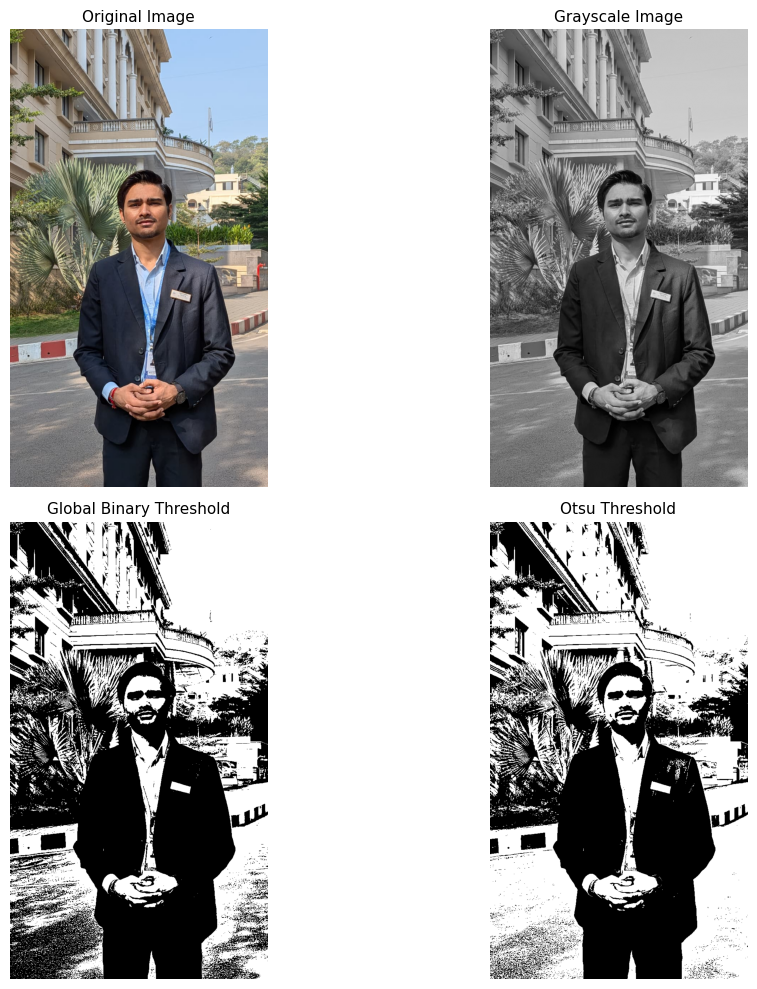

True

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(original)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(gray, cmap="gray")
axes[0, 1].set_title("Grayscale Image")

axes[1, 0].imshow(binary_threshold, cmap="gray")
axes[1, 0].set_title("Global Binary Threshold")

axes[1, 1].imshow(otsu_threshold, cmap="gray")
axes[1, 1].set_title("Otsu Threshold")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_thresholding_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Save binary masks
cv2.imwrite(str(OUTPUT_DIR / "08_binary_threshold.png"), binary_threshold)
cv2.imwrite(str(OUTPUT_DIR / "09_otsu_threshold.png"), otsu_threshold)
cv2.imwrite(str(OUTPUT_DIR / "10_adaptive_threshold.png"), adaptive_threshold)

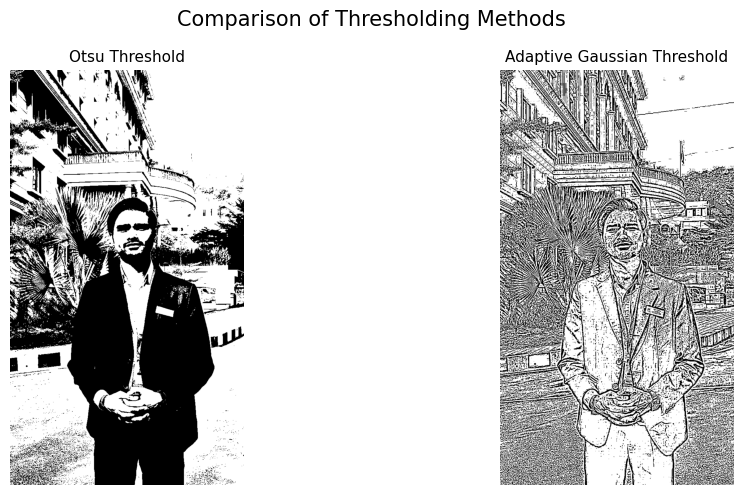

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(otsu_threshold, cmap="gray")
axes[0].set_title("Otsu Threshold")

axes[1].imshow(adaptive_threshold, cmap="gray")
axes[1].set_title("Adaptive Gaussian Threshold")

for ax in axes:
    ax.axis("off")

plt.suptitle("Comparison of Thresholding Methods", fontsize=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "11_adaptive_threshold_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Observation

Global thresholding applies one threshold to the entire image.
Otsu's method selects a threshold automatically based on the grayscale
histogram. Adaptive thresholding calculates thresholds for local regions,
which can be useful when illumination varies across the image.

The quality of each binary mask depends on the contrast and lighting
conditions of the original photograph.

## Part 4: Morphological Operations

Morphological operations process the shapes in a binary image.

- Erosion shrinks foreground regions.
- Dilation expands foreground regions.
- Opening performs erosion followed by dilation and can remove small
  foreground noise.
- Closing performs dilation followed by erosion and can fill small
  gaps or holes.

These operations use a structuring element, also called a kernel.

In [15]:
# Use the Otsu binary mask
binary_image = otsu_threshold.copy()

# Structuring element
kernel = np.ones((5, 5), np.uint8)

# Morphological operations
erosion = cv2.erode(binary_image, kernel, iterations=1)
dilation = cv2.dilate(binary_image, kernel, iterations=1)
opening = cv2.morphologyEx(binary_image, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary_image, cv2.MORPH_CLOSE, kernel)

print("Erosion, dilation, opening, and closing completed.")

Erosion, dilation, opening, and closing completed.


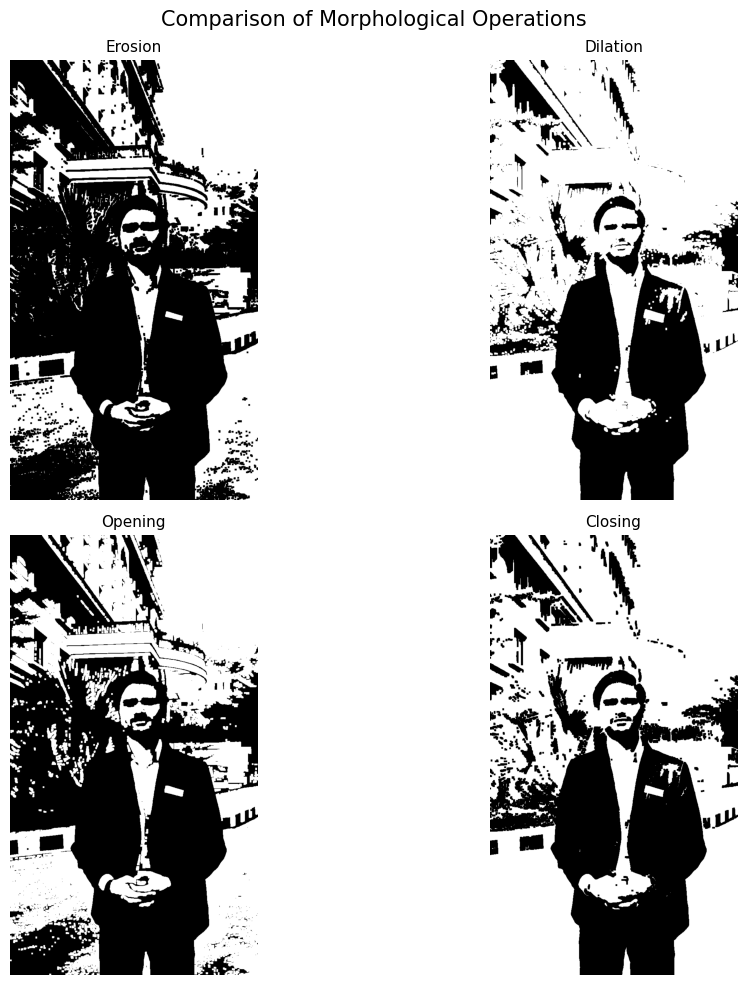

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(erosion, cmap="gray")
axes[0, 0].set_title("Erosion")

axes[0, 1].imshow(dilation, cmap="gray")
axes[0, 1].set_title("Dilation")

axes[1, 0].imshow(opening, cmap="gray")
axes[1, 0].set_title("Opening")

axes[1, 1].imshow(closing, cmap="gray")
axes[1, 1].set_title("Closing")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle("Comparison of Morphological Operations", fontsize=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "12_morphological_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Save outputs
for name, image in {
    "13_erosion.png": erosion,
    "14_dilation.png": dilation,
    "15_opening.png": opening,
    "16_closing.png": closing
}.items():
    cv2.imwrite(str(OUTPUT_DIR / name), image)

### Observation

Compare how the foreground shapes change after each operation.
Erosion reduces foreground regions, while dilation expands them.
Opening may remove small white noise, and closing may connect nearby
foreground regions or fill small dark gaps.

The effectiveness of these operations depends on the structuring
element size and the shapes present in the binary image.

## Part 5: Canny Edge Detection

Canny edge detection identifies strong intensity changes in an image.
It uses gradient information and two thresholds to determine which
edges should be retained.

The resulting edge map can highlight boundaries and object outlines.

In [17]:
# Apply a small Gaussian blur to reduce noise before edge detection
gray_blurred = cv2.GaussianBlur(gray, (5, 5), 1.0)

# Canny edge detection
edges = cv2.Canny(
    gray_blurred,
    threshold1=50,
    threshold2=150
)

print("Canny edge detection completed.")

Canny edge detection completed.


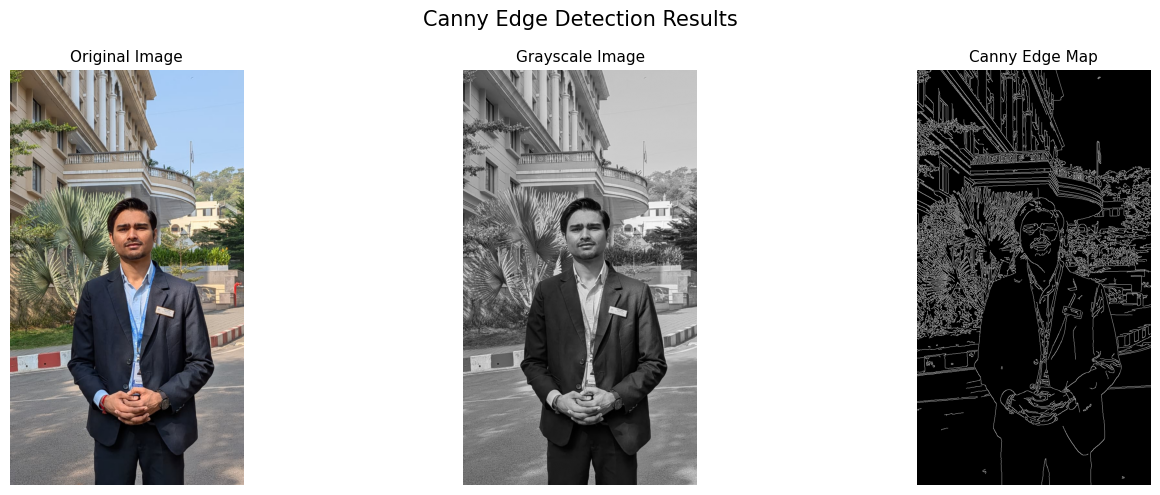

True

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original)
axes[0].set_title("Original Image")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale Image")

axes[2].imshow(edges, cmap="gray")
axes[2].set_title("Canny Edge Map")

for ax in axes:
    ax.axis("off")

plt.suptitle("Canny Edge Detection Results", fontsize=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "17_canny_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

cv2.imwrite(str(OUTPUT_DIR / "18_canny_edges.png"), edges)

### Observation

The Canny edge map highlights intensity boundaries in the photograph.
The number and continuity of detected edges depend on image contrast,
preprocessing, and the selected threshold values.

## Part 6: Watershed Segmentation

Watershed segmentation separates image regions using foreground and
background markers.

The process involves thresholding, morphological cleanup, distance
transform, marker generation, and watershed boundary detection.

The method is especially useful for separating touching objects when
suitable foreground and background regions can be identified.

In [19]:
# Use the original image as the watershed input
watershed_input = original.copy()

# Create a binary image using Otsu thresholding
_, watershed_binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove small noise and separate some connected regions
watershed_kernel = np.ones((3, 3), np.uint8)

opening_ws = cv2.morphologyEx(
    watershed_binary,
    cv2.MORPH_OPEN,
    watershed_kernel,
    iterations=2
)

# Identify sure background
sure_bg = cv2.dilate(
    opening_ws,
    watershed_kernel,
    iterations=3
)

# Distance transform for foreground regions
distance = cv2.distanceTransform(
    opening_ws,
    cv2.DIST_L2,
    5
)

# Identify sure foreground
_, sure_fg = cv2.threshold(
    distance,
    0.4 * distance.max(),
    255,
    0
)

sure_fg = sure_fg.astype(np.uint8)

# Unknown region lies between foreground and background
unknown = cv2.subtract(sure_bg, sure_fg)

# Label connected foreground components
num_labels, markers = cv2.connectedComponents(sure_fg)

# Reserve zero for unknown regions
markers = markers + 1
markers[unknown == 255] = 0

print("Foreground components detected (excluding background):", num_labels - 1)

Foreground components detected (excluding background): 4


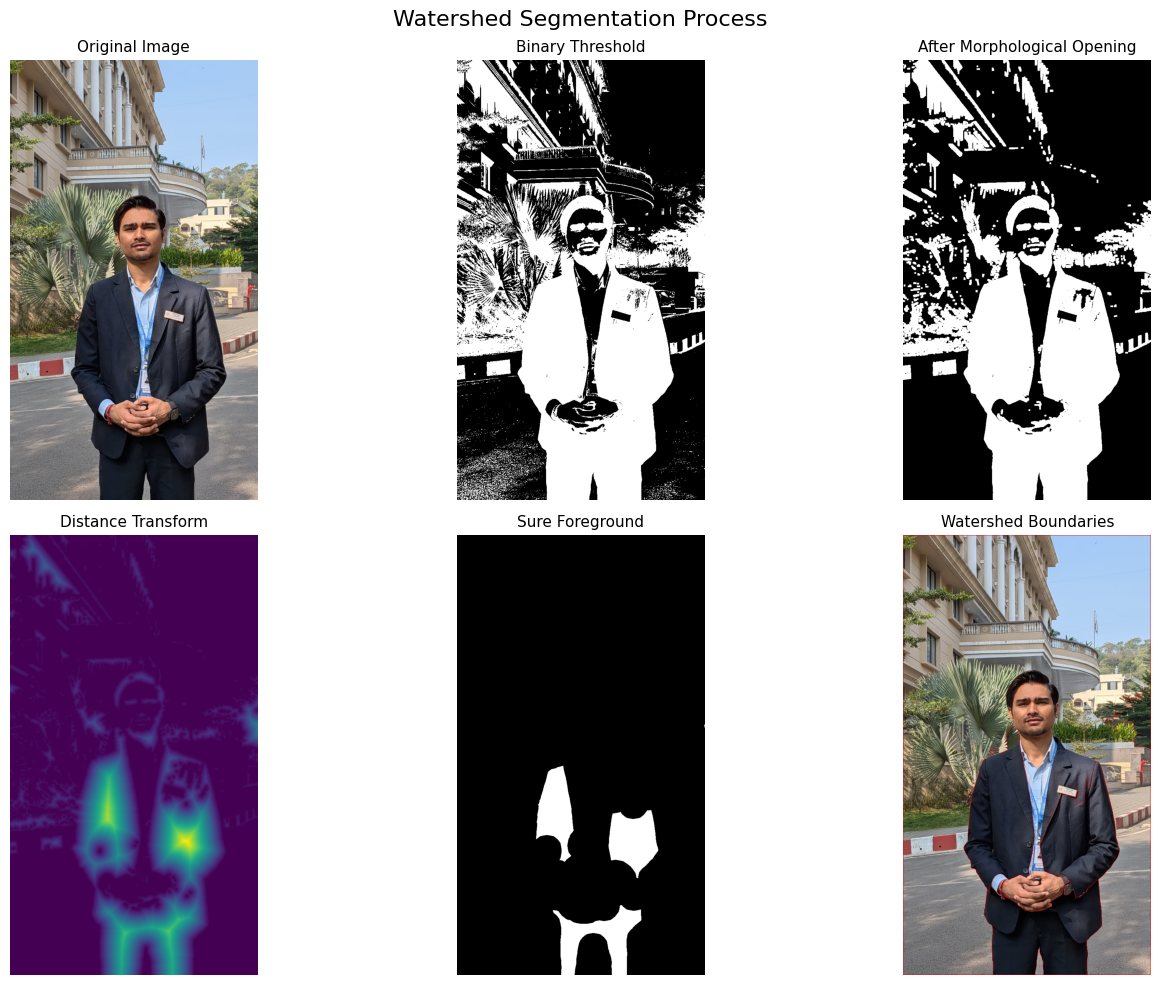

True

In [20]:
# Watershed modifies marker labels in place
watershed_markers = markers.copy()
cv2.watershed(watershed_input, watershed_markers)

# Mark watershed boundaries in red
watershed_result = watershed_input.copy()
watershed_result[watershed_markers == -1] = [255, 0, 0]

# Visualize the intermediate and final results
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0, 0].imshow(original)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(watershed_binary, cmap="gray")
axes[0, 1].set_title("Binary Threshold")

axes[0, 2].imshow(opening_ws, cmap="gray")
axes[0, 2].set_title("After Morphological Opening")

axes[1, 0].imshow(distance, cmap="viridis")
axes[1, 0].set_title("Distance Transform")

axes[1, 1].imshow(sure_fg, cmap="gray")
axes[1, 1].set_title("Sure Foreground")

axes[1, 2].imshow(watershed_result)
axes[1, 2].set_title("Watershed Boundaries")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle("Watershed Segmentation Process", fontsize=16)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "19_watershed_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "20_watershed_result.png"),
    cv2.cvtColor(watershed_result, cv2.COLOR_RGB2BGR)
)

### Observation

The watershed algorithm identifies boundaries between labeled regions.
Red lines indicate watershed boundaries in the displayed result.

The segmentation quality depends on the suitability of the binary mask
and markers. If the image does not contain distinct or touching objects,
the result may not represent meaningful object segmentation. In that
case, repeat the experiment using a suitable original photograph of
multiple objects and document which image was used.

In [21]:
print("Task 1 output folder:")
print(OUTPUT_DIR.resolve())

saved_files = sorted(
    file for file in OUTPUT_DIR.iterdir()
    if file.is_file()
)

print("\nSaved files:")
for file in saved_files:
    print("-", file.name)

print(f"\nTotal output files: {len(saved_files)}")

Task 1 output folder:
D:\Projects\CV\outputs\task1_restoration_segmentation

Saved files:
- 01_original_image.png
- 02_noise_comparison.png
- 03_gaussian_noisy.png
- 04_salt_pepper_noisy.png
- 05_restoration_comparison.png
- 07_thresholding_comparison.png
- 08_binary_threshold.png
- 09_otsu_threshold.png
- 10_adaptive_threshold.png
- 11_adaptive_threshold_comparison.png
- 12_morphological_comparison.png
- 13_erosion.png
- 14_dilation.png
- 15_opening.png
- 16_closing.png
- 17_canny_comparison.png
- 18_canny_edges.png
- 19_watershed_comparison.png
- 20_watershed_result.png

Total output files: 19


## Conclusion

This experiment investigated image restoration and segmentation using
Gaussian noise, salt-and-pepper noise, Gaussian filtering, median
filtering, thresholding, morphological operations, Canny edge detection,
and watershed segmentation.

PSNR and SSIM were used to compare restoration results with the original
reference image. Subplot comparisons were used to visualize the effects
of each processing technique.

The results demonstrate that the choice of filtering, thresholding,
structuring element, and segmentation markers affects the quality of
the processed image.